# **Importing Libraries**

In [124]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import time

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier

from sklearn.preprocessing import MinMaxScaler
from scipy.sparse import hstack, csr_matrix

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report

# **Load the Data**

In [125]:
'''url = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/All_Beauty.jsonl.gz"

df = pd.read_json(
    url,
    lines=True,
    compression="gzip",
    nrows=50000
)'''

'url = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/All_Beauty.jsonl.gz"\n\ndf = pd.read_json(\n    url,\n    lines=True,\n    compression="gzip",\n    nrows=50000\n)'

In [126]:
'''# Export the DataFrame to a CSV file
output_csv_path = '/content/All_Beauty.csv'
df.to_csv(output_csv_path, index=False)

print(f"Successfully saved {len(df)} rows to {output_csv_path}")'''

'# Export the DataFrame to a CSV file\noutput_csv_path = \'/content/All_Beauty.csv\'\ndf.to_csv(output_csv_path, index=False)\n\nprint(f"Successfully saved {len(df)} rows to {output_csv_path}")'

# **Loading Dataset**

In [127]:
data=pd.read_csv('/content/All_Beauty.csv')
print(data.columns)
print(data.dtypes)
data.isna().sum()
data.sample(10,random_state=42)

Index(['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id',
       'timestamp', 'helpful_vote', 'verified_purchase'],
      dtype='object')
rating               float64
title                 object
text                  object
images                object
asin                  object
parent_asin           object
user_id               object
timestamp              int64
helpful_vote           int64
verified_purchase       bool
dtype: object


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
154430,5.0,Nice,Surprisingly good quality.,[],B071GQWJMD,B071GQWJMD,AGPC4MJADBVQQ432BW6ECFYRFWQA,1573184185660,0,True
95113,5.0,Five Stars,wonderful,[],B00JY2FGBS,B00JY2FGBS,AGLOELAEJKZH2YYI6WM3MR2HQQZQ,1417804303000,0,True
138537,5.0,Works great!,Really like all the different sizes! Does exac...,[],B019GM3N5Q,B019GM3N5Q,AGXKSLHTSATQZNDNKCPVPMD2YVCA,1501888319770,0,True
82202,5.0,I absolutely love these lashes,I absolutely love these lashes! Perfect for an...,[],B06XD9TTK3,B06XD9TTK3,AGDUUC6HFN6HWNCFXPALS3ORJCHA,1515259503640,0,True
96569,2.0,Stinky but good,I love these brushes! Soft and good quality. T...,[],B00Y6ZJKTC,B00Y6ZJKTC,AG72TUCHBP5BYZATTKDVKSZVBNMQ,1454117350000,0,True
15627,5.0,Fun headbands!,My child loves animals (especially cats!) and ...,[],B07JH79FM5,B07JH79FM5,AGZS22WNDBIVLMQDIBG4ILXILONQ,1579393242928,0,True
61675,2.0,"Performs like ""ToothSoap"" but just too expensive.","I would like to get behind this product, but I...",[],B00XRUBGZ8,B00XRUBGZ8,AHVYTCHOHBLAVIHS5HXS3NZAFZBA,1452715445000,2,True
63384,5.0,Love shopping,My daughter will love them,[],B088GPQG7P,B088GPQG7P,AESKUZVSUNKDWJKNB4W6HMQQWFBA,1604552058760,0,True
30831,4.0,Four Stars,GOOD,[],B007ONF43E,B007ONF43E,AFDI53RHTNRWBZ56CAVT3IAPAODQ,1460947132000,0,True
139077,3.0,iworks but not for the impatient,"I have uses this on regular polish, glitter, m...",[],B01AYTGWA8,B01AYTGWA8,AELF5JOI5MGYNNEHON62YDV6GE7A,1468775382000,0,True


**Counting the rating**

In [128]:
# Convert the rating column to numeric, forcing invalid parsing to NaN
data["rating"] = pd.to_numeric(data["rating"], errors='coerce')

# Calculate value counts and sort the index numerically
print(data["rating"].value_counts().sort_index())

rating
1.0     23546
2.0     12532
3.0     18291
4.0     25989
5.0    125074
Name: count, dtype: int64


**Changing it into sentiment values-0 & 1**

In [129]:
data=data[data['rating']!=3].copy()   #it will create a copy with ratings 1,2,4,5 only
#step1: Add a new column ,and set the column to 0
#step2: then change it to other values according to coditions
data['sentiment']=0
data.loc[data['rating']>3,'sentiment']=1
#checking the result
data.sample(10,random_state=42)


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,sentiment
84986,5.0,Fantastic....larger than pictured.,Brings me back to the 70s.....my favorite.,[],B013V7DGSG,B013V7DGSG,AFQ7IOHJRX3HAKNRNSMQ5MJYM3DQ,1500471274097,0,True,1
101727,5.0,Super cute bows,I bought these for my daughter when she was a ...,[],B009A2YIWU,B009A2YIWU,AECBFYMTAPJ6TCJWO7Y3XDPPNWKQ,1446263677000,0,True,1
193445,5.0,"Gorgeous, just the right moisture!",Gorgeous color and formula. Just the right amo...,[],B07BMB9X1Q,B07BMB9X1Q,AGNJT2B3IRAN2K4UTBXHJ4UOHPSQ,1634353624025,0,False,1
60077,4.0,Good buy!,I have short hair and difficulty lifting my ar...,[],B001MP0QH4,B01N4885PD,AEOGKW43SOPXIG4Q7KCKTE7IU6EQ,1489092815000,0,True,1
187304,5.0,Excellent.,Works great. Thanks.,[],B09137RFQ1,B09137RFQ1,AE3WKNYB3LPFF4LYCLBPTQZAYJNA,1644611913552,0,True,1
126451,5.0,I’m seeing a difference immediately,"I’ve struggled with acne for a long time, as w...",[],B06WD5J8KY,B06WD5J8KY,AEJSJ5YITRWJ7CE5FGDC2PZ3K6SQ,1598539973109,3,True,1
40690,5.0,"great coverage, size and arrived early",I was gifted a taste concealer in the past but...,[],B00TUPJQUG,B07JHHJXMG,AFCXQ6DMQWDAROASWGITI3PU3GEQ,1601581979291,1,True,1
153004,2.0,I had admired someone's hair and she recommend...,I urge anyone thinking of using this product t...,[],B001540XWK,B001540XWK,AGCUYCUYPAGGCLHJ6JTVYHGRJEVA,1441210034000,1,False,0
34968,2.0,It’s alright,This is awesome for the price but they seem to...,[],B083GJ4Q3H,B083GJ4Q3H,AEZVNNT5HXP7R7RSPEWQT4GFCJ3Q,1608086826030,0,True,0
177049,4.0,Argan oil Shampoo,I am pleased with this shampoo. I have chemica...,[],B012Q9NGE4,B012Q9NGE4,AEUZUC7567S4DO24R5NTR57O4FKQ,1481458506000,0,True,1


sentiment
0     36078
1    151063
Name: count, dtype: int64


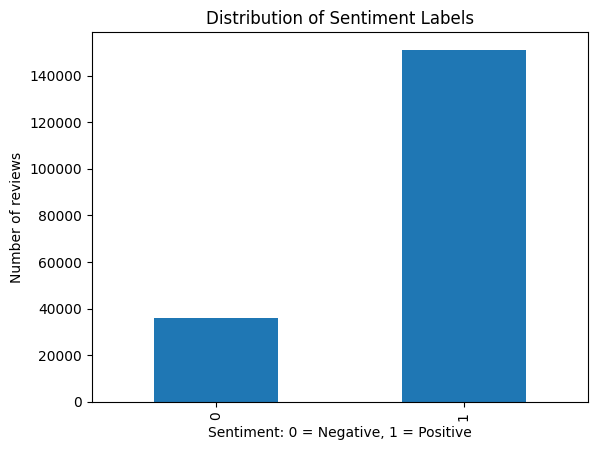

In [130]:
#count the values
print(data["sentiment"].value_counts().sort_index())

data["sentiment"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xlabel("Sentiment: 0 = Negative, 1 = Positive")
plt.ylabel("Number of reviews")
plt.title("Distribution of Sentiment Labels")
plt.show()

# **Data Cleaning**

In [131]:
data.isna().sum()


,0
rating,0
title,36
text,32
images,0
asin,0
parent_asin,0
user_id,0
timestamp,0
helpful_vote,0
verified_purchase,0


**here we have 2 columns with null values, so our idea is to fill it by empty strings** <br>
*Mostly this thing depends on title and text data ,also on star. So if a row has nan value in title and text column , we will remove that row*

In [132]:
#filling title column
data['title']=data['title'].fillna("")
#filling text column
data['text']=data['text'].fillna("")
#removing rows
data= data[
    (data["title"].str.strip() != "") |
    (data["text"].str.strip() != "")
].copy()

*Now we will create a new column combining this title and text data*

In [133]:
# Create a new column combining title and review body
data["full_review"] = data["title"] + " " + data["text"]

# Remove extra spaces at the beginning and end
data["full_review"] = data["full_review"].str.strip()
data[["title", "text", "full_review"]].head()

,title,text,full_review
0,Such a lovely scent but not overpowering.,This spray is really nice. It smells really go...,Such a lovely scent but not overpowering. This...
1,Works great but smells a little weird.,"This product does what I need it to do, I just...",Works great but smells a little weird. This pr...
2,Yes!,"Smells good, feels great!","Yes! Smells good, feels great!"
3,Synthetic feeling,Felt synthetic,Synthetic feeling Felt synthetic
4,A+,Love it,A+ Love it


*Make verified_purchase to 0,1*

In [134]:
data["verified_purchase"] = (data["verified_purchase"].fillna(False).astype(int))
# print(data["verified_purchase"].value_counts())
# data["uppercase_count"] = data["full_review"].str.count(r"[A-Z]")
# #in 0-th index example ,it has 9 uppercase letters
# print(data["uppercase_count"])

### **Analyzing Uppercase Counts**

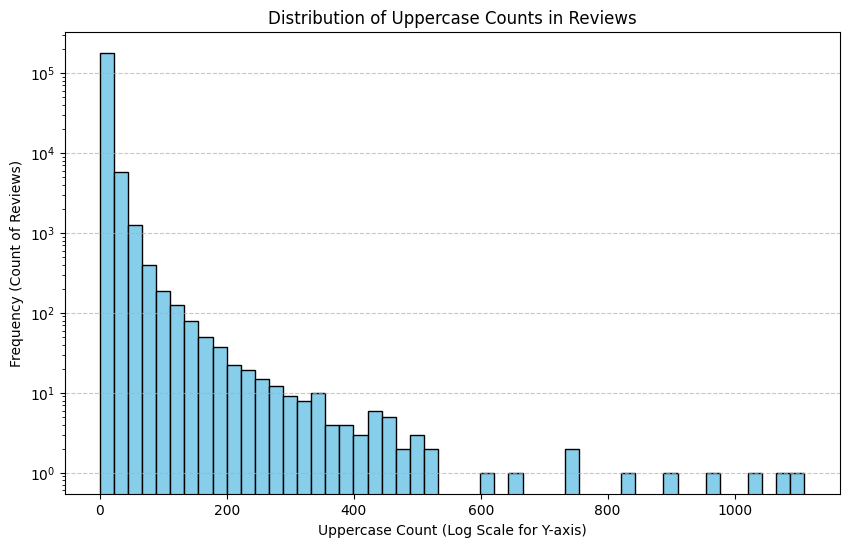

In [135]:
# Recompute uppercase_count since the earlier feature extraction step was commented out
data['uppercase_count'] = data['full_review'].str.count(r'[A-Z]')

# Plot the histogram of uppercase counts
plt.figure(figsize=(10, 6))
# Using a logarithmic scale for the y-axis because of potential extreme outliers/long tail
plt.hist(data['uppercase_count'], bins=50, color='skyblue', edgecolor='black', log=True)
plt.xlabel('Uppercase Count (Log Scale for Y-axis)')
plt.ylabel('Frequency (Count of Reviews)')
plt.title('Distribution of Uppercase Counts in Reviews')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Conclusion from this plot :** <br> *Distribution is strongly right skewed*

rating
1.0    7.686698
2.0    6.841605
4.0    7.524801
5.0    6.921202
Name: uppercase_count, dtype: float64


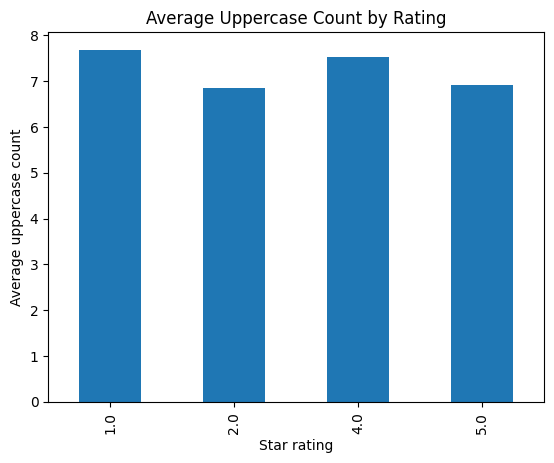

In [136]:
average_uppercase = data.groupby("rating")["uppercase_count"].mean()

print(average_uppercase)

average_uppercase.plot(kind="bar")
plt.xlabel("Star rating")
plt.ylabel("Average uppercase count")
plt.title("Average Uppercase Count by Rating")
plt.show()

**Conclusion from bar plot :** <br> *Can't say much*

In [137]:
# Ensure 'rating' is entirely numeric and drop rows with invalid ratings
data['rating'] = pd.to_numeric(data['rating'], errors='coerce')
print(data['rating'])
clean_data = data.dropna(subset=['rating'])

# Calculate correlation between rating and uppercase count
correlation = clean_data['rating'].corr(clean_data['uppercase_count'])
print(f"Correlation between Rating and Uppercase Count: {correlation:.4f}")

0         5.0
1         4.0
2         5.0
3         1.0
4         5.0
         ... 
205426    4.0
205427    1.0
205429    5.0
205430    5.0
205431    5.0
Name: rating, Length: 187132, dtype: float64
Correlation between Rating and Uppercase Count: -0.0150


*Correlation is almost equal to 0*

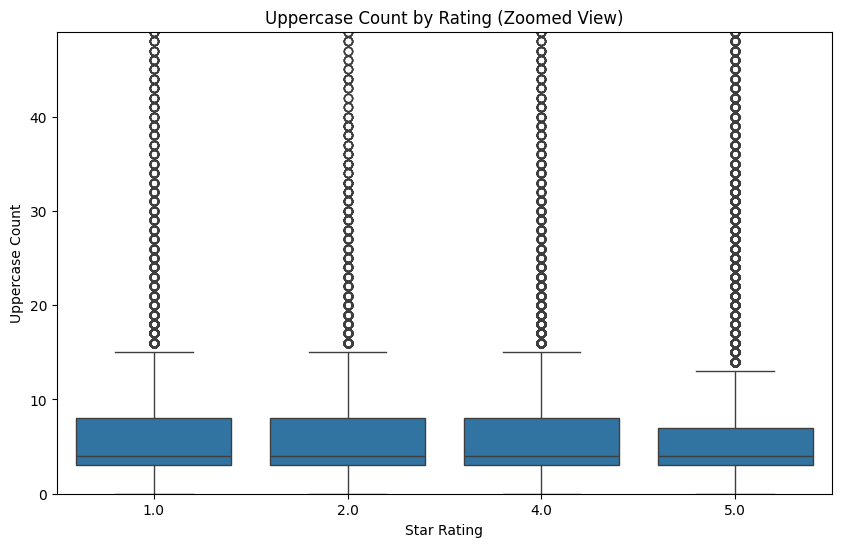

In [138]:
import matplotlib.pyplot as plt
import seaborn as sns

upper_limit = data["uppercase_count"].quantile(0.99)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=data,
    x="rating",
    y="uppercase_count"
)

plt.ylim(0, upper_limit)

plt.xlabel("Star Rating")
plt.ylabel("Uppercase Count")
plt.title("Uppercase Count by Rating (Zoomed View)")

plt.show()

*meadian is also almost same for all ratings*

# **Splitting the data**

In [139]:
train_data, test_data = train_test_split(
    data,
    test_size=0.2,
    random_state=42,  # splitting the data randomly
    stratify=data["sentiment"]
    #This ensures that the proportion of each sentiment class remains the same in both the training and testing sets as it is in the original dataset.
)

#As we are splitting randomy so we have to reset the row indices
train_data = train_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

# Create target variables
y_train = train_data["sentiment"]
y_test = test_data["sentiment"]

print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))

Training rows: 149705
Testing rows: 37427


image.png

***Model 1(Bag of Words):Vocabulary-based featires using review text***

*vocabulary-based vectorizer*

In [140]:
vectorizer1=CountVectorizer(max_features=20000,stop_words='english')


**Example:**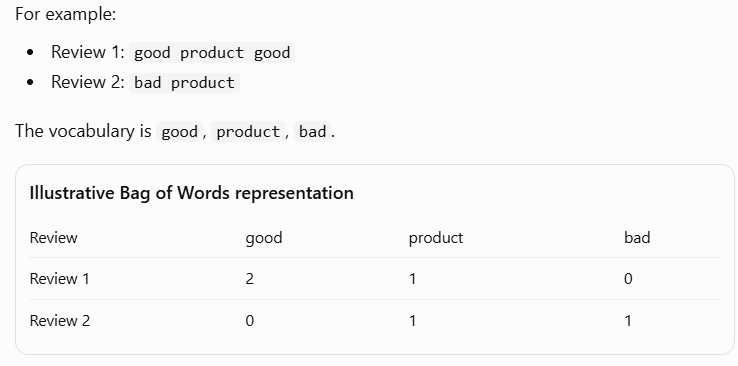

In [141]:
# Learn the vocabulary and convert training reviews into word counts
X_train_bow=vectorizer1.fit_transform(train_data['text'].fillna(""))  #fit_transform does it
print('Training Matrix:',X_train_bow.shape)
# Convert test reviews using the SAME vocabulary
X_test_bow=vectorizer1.transform(test_data['text'].fillna(""))   #convert test reviews using the Same vocabulary
print('Training Matrix:',X_test_bow.shape)

'''We must not learn the vocabulary from the test set because that would leak
 information from the test data into the training process.'''

Training Matrix: (149705, 20000)
Training Matrix: (37427, 20000)


'We must not learn the vocabulary from the test set because that would leak\n information from the test data into the training process.'

***Model 2:TF-IDF***  <br> *TF-IDF also represents reviews using words, but adjusts their weights according to how common or informative the words are across the training reviews.*

In [142]:
#Extract review text
X_train_text = train_data["full_review"]
X_test_text = test_data["full_review"]

In [143]:
tfidf_vectorizer=TfidfVectorizer(max_features=20000,stop_words='english')

#Learn TF-IDF vocabulary and weights from training data
X_train_tfidf=tfidf_vectorizer.fit_transform(X_train_text)

#Transform this for test reviews
X_test_tfidf=tfidf_vectorizer.transform(X_test_text)

print('Training matrix: ',X_train_tfidf.shape)
print('Test matrix: ',X_test_tfidf.shape)

Training matrix:  (149705, 20000)
Test matrix:  (37427, 20000)


***Model 3:TF-IDF +Numerical features***

**Step 1:** *Numerical Features*

In [144]:
# Count the number of words
train_data["word_count"] = train_data["full_review"].str.split().str.len()
# print(train_data["word_count"])
test_data["word_count"] = test_data["full_review"].str.split().str.len()

# Count uppercase letters
train_data["uppercase_count"] = train_data["full_review"].str.count(r"[A-Z]")
test_data["uppercase_count"] = test_data["full_review"].str.count(r"[A-Z]")

# Count exclamation marks
train_data["exclamation_count"] = train_data["full_review"].str.count("!")
test_data["exclamation_count"] = test_data["full_review"].str.count("!")

# Count question marks
train_data["question_count"] = train_data["full_review"].str.count(r"\?")
test_data["question_count"] = test_data["full_review"].str.count(r"\?")

**Step 2**

In [145]:
#Select the 4 numerical columns
numerical_columns=['word_count','uppercase_count','exclamation_count','question_count']
X_train_num=train_data[numerical_columns]
X_test_num=test_data[numerical_columns]
print(X_train_num.shape)
# print(X_test_num.shape)

(149705, 4)


**Step 3:** *Scaling the features*

In [146]:
scaler=MinMaxScaler()
#X_scaled=[(X-X_min)/(X_max -X_min)]*(Max-Min) + Min

#Learn scaling values from training data
X_train_num_scaled=scaler.fit_transform(X_train_num)
#Apply the same scaling to test data
X_test_num_scaled=scaler.fit_transform(X_test_num)
# print(X_train_num_scaled.shape)


**Step 4:** *Combining the numerical features wih TF-IDF*

In [147]:
# Convert numerical arrays to sparse matrices
X_train_num_sparse = csr_matrix(X_train_num_scaled)
'''print(X_train_num_sparse.shape)'''
#csr_matrix: Converts dense or standard numerical arrays into Compressed Sparse Row format.
X_test_num_sparse = csr_matrix(X_test_num_scaled)

# Combine TF-IDF and numerical features
X_train_combined = hstack([ #hstack: Combines matrices side-by-side (horizontally). For this to work, both matrices must have the exact same number of rows (samples).
    X_train_tfidf,
    X_train_num_sparse
]).tocsr() #tocsr(): Ensures the final output retains an efficient sparse structure ready for Scikit-Learn models.

X_test_combined = hstack([
    X_test_tfidf,
    X_test_num_sparse
]).tocsr()

print("Combined training matrix:", X_train_combined.shape)
print("Combined testing matrix:", X_test_combined.shape)

Combined training matrix: (149705, 20004)
Combined testing matrix: (37427, 20004)


# **Training our models on :** <br> *1.Logistic Regression <br> 2.Naive Bayes <br> 3.K-NN*

*Final Checking before entering the classifiers*

In [148]:
print("Size of Bag of Words:", X_train_bow.shape, X_test_bow.shape)
print("Size of TF-IDF:", X_train_tfidf.shape, X_test_tfidf.shape)
print("Size of TF-IDF & Numerical:", X_train_combined.shape, X_test_combined.shape)

print("Size of Training labels:", y_train.shape)
print("Size of Testing labels:", y_test.shape)

Size of Bag of Words: (149705, 20000) (37427, 20000)
Size of TF-IDF: (149705, 20000) (37427, 20000)
Size of TF-IDF & Numerical: (149705, 20004) (37427, 20004)
Size of Training labels: (149705,)
Size of Testing labels: (37427,)


*Feature Reprsentations  & Classifiers*

In [149]:
#Features
feature_models ={"Bag_of_words":(X_train_bow,X_test_bow),
                 "TF-IDF":(X_train_tfidf,X_test_tfidf),
                 "TF-IDF + Numerical":(X_train_combined,X_test_combined)
                 }

#Classifiers
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "K-NN": KNeighborsClassifier(n_neighbors=5,algorithm="brute",  #use brute force method to find distance
                                 metric="cosine",   #1-(u.v/||u||.||v||)
                                 n_jobs=-1)  #use all processor
}

*Train and evaluate the 9 models*

In [ ]:
results = []

for model_name, matrices in feature_models.items():
    X_train_current = matrices[0]
    X_test_current = matrices[1]
    for classifier_name, classifier in classifiers.items():
        print("Training:", model_name, "+", classifier_name)

        # Create a fresh classifier for this experiment
        model = classifier.__class__(**classifier.get_params())

        # Start timer
        start_time = time.time()

        # Train the model
        model.fit(X_train_current, y_train)

        # Predict labels for test reviews
        predictions = model.predict(X_test_current)

        # Stop timer
        '''Time tells you how computationally expensive each model is.
        It helps to compare not just which model predicts better,
        but also how long it takes to train and make predictions.'''
        elapsed_time = time.time() - start_time

        # Calculate metrics
        accuracy = accuracy_score(y_test, predictions)
        precision = precision_score(y_test,predictions,average="macro",zero_division=0)
        recall = recall_score(y_test,predictions,average="macro",zero_division=0)
        macro_f1 = f1_score(y_test,predictions,average="macro",zero_division=0)

        # Save the results
        results.append({
            "Feature Model": model_name,
            "Algorithm": classifier_name,
            "Accuracy": accuracy,
            "Macro Precision": precision,
            "Macro Recall": recall,
            "Macro F1": macro_f1,
            "Time (seconds)": elapsed_time
        })

        print("Accuracy:", round(accuracy, 4))
        print("Macro F1:", round(macro_f1, 4))
        print("Time:", round(elapsed_time, 2), "seconds")

Training: Bag_of_words + Logistic Regression
Accuracy: 0.9125
Macro F1: 0.8495
Time: 9.02 seconds
Training: Bag_of_words + Naive Bayes
Accuracy: 0.9002
Macro F1: 0.83
Time: 0.08 seconds
Training: Bag_of_words + K-NN


*Compare all Results*

In [ ]:
results_data = pd.DataFrame(results)
results_data = results_data.sort_values(by="Macro F1",ascending=False)
print(results_data)

# Extended Comparsion:

In [ ]:
import matplotlib.pyplot as plt

results_data["Experiment"] = (results_data["Feature Model"]+ " + "+ results_data["Algorithm"])
plt.figure(figsize=(14, 6))

plt.bar(results_data["Experiment"],results_data["Macro F1"])

plt.xticks(rotation=75, ha="right")
plt.ylabel("Macro F1 Score")
plt.title("Comparison of 9 Sentiment Classification Experiments")
plt.tight_layout()
plt.show()

**Idenify the best experiment**

In [ ]:
best_result = results_data.iloc[0]

print("Best feature model:", best_result["Feature Model"])
print("Best algorithm:", best_result["Algorithm"])
print("Accuracy:", round(best_result["Accuracy"], 4))
print("Macro F1:", round(best_result["Macro F1"], 4))